<a href="https://colab.research.google.com/github/matiasmorgan1/Master-s-by-Research/blob/main/CMEMS_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1️⃣ Install required packages
!pip install xarray netcdf4 plotly pandas cartopy
!pip install geopandas shapely pyproj fiona

# 2️⃣ Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 3️⃣ Import libraries
import xarray as xr
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyproj import Transformer, CRS
from scipy.interpolate import griddata
import geopandas as gpd
from shapely.geometry import Polygon, LineString

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 51.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 74.8 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
# ---------------------------------------------
# Interactive SST Anomaly Map with Time Slider (2014-present)
# ---------------------------------------------

# 1️⃣ Set file path for the new dataset
nc_file = '/content/drive/MyDrive/MRes_OceanData/CMEMS_OceanTemp_1991_2024.nc'

# 2️⃣ Load dataset
ds = xr.open_dataset(nc_file)
print(ds)  # inspect variables

# 3️⃣ Define region bounds (full SE Greenland)
lat_min = 61
lat_max = 67
lon_min = -44.1
lon_max = -36

# 4️⃣ Subset dataset by region
ds_region = ds.sel(
    latitude=slice(lat_min, lat_max),
    longitude=slice(lon_min, lon_max)
)

# 5️⃣ Select depth (surface/subsurface)
sst = ds_region['thetao'].sel(depth=250, method='nearest')

# 6️⃣ Resample to monthly averages (reduces slider frames)
sst_monthly = sst.resample(time='1M').mean()

# 7️⃣ Compute baseline climatology 1991-2010
baseline_period = ds_region.sel(time=slice('1991-01-01','2011-12-31'))
baseline_sst = baseline_period['thetao'].sel(depth=300, method='nearest')
baseline_monthly = baseline_sst.groupby('time.month').mean(dim='time')

# 8️⃣ Compute anomalies
sst_anomaly = sst_monthly.groupby('time.month') - baseline_monthly

# 9️⃣ Convert to DataFrame for Plotly
df_anom = sst_anomaly.to_dataframe().reset_index()

# 9️⃣a Filter for 2014-present
df_anom = df_anom[df_anom['time'] >= '2014-01-01']

# 10️⃣ Plot interactive map with time slider
fig = px.scatter(
    df_anom,
    x='longitude',
    y='latitude',
    color='thetao',
    animation_frame='time',
    color_continuous_scale='RdBu_r',  # diverging scale for anomalies
    title='Sea Surface Temperature Anomaly (°C) SE Greenland (2014-present)',
    labels={'thetao':'300m depth Anomaly (°C)','longitude':'Longitude','latitude':'Latitude'},
    width=800,
    height=600
)

fig.update_layout(
    yaxis=dict(scaleanchor="x", scaleratio=1),
    template='plotly_white'
)

fig.show()


<xarray.Dataset> Size: 242MB
Dimensions:    (time: 408, depth: 40, latitude: 57, longitude: 65)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1991-01-01 1991-02-01 ... 2024-12-01
  * depth      (depth) float32 160B -0.0 2.0 4.0 6.0 ... 3e+03 3.5e+03 4e+03
  * latitude   (latitude) float32 228B 60.0 60.12 60.25 ... 66.75 66.88 67.0
  * longitude  (longitude) float32 260B -44.0 -43.88 -43.75 ... -36.12 -36.0
Data variables:
    thetao     (time, depth, latitude, longitude) float32 242MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Arctic Ocean Physics Reanalysis, 12.5km monthly mean
    institution:       NERSC, Jahnebakken 3, N-5007 Bergen, Norway
    source:            NERSC-HYCOM model fields
    references:        https://doi.org/10.48670/moi-00007
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  ARCTIC_MULTIYEAR_PHY_002_003
    subset:datasetId:  cmems_mod_arc_phy_my_topaz4_P1M_202506
    subset:

/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


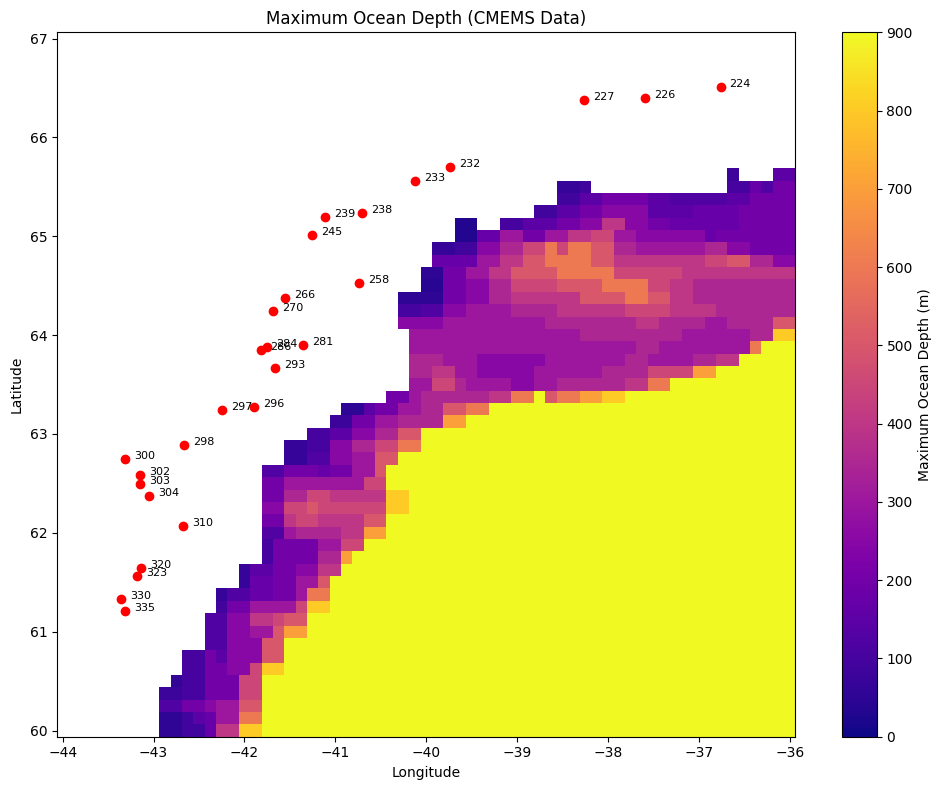

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# --- Load dataset ---
path = "/content/drive/MyDrive/MRes_OceanData/CMEMS_OceanTemp_1991_2024.nc"
ds = xr.open_dataset(path)

# --- Glacier coordinates ---
glacier_coords = {
    226: (66.401121, -37.597138),
    284: (63.875912, -41.751149),
    303: (62.49107, -43.15229),
    320: (61.639677, -43.136743),
    323: (61.5672, -43.178178),
    245: (65.012344, -41.251558),
    286: (63.852942, -41.81786),
    296: (63.271613, -41.893431),
    233: (65.559332, -40.125435),
    238: (65.234993, -40.706336),
    232: (65.697643, -39.734977),
    300: (62.746836, -43.313508),
    304: (62.370736, -43.051618),
    310: (62.067368, -42.672088),
    270: (64.243946, -41.686908),
    335: (61.209418, -43.313418),
    297: (63.243014, -42.250839),
    298: (62.892129, -42.663693),
    281: (63.902382, -41.356373),
    293: (63.671452, -41.66253),
    224: (66.514517, -36.7617),
    239: (65.194252, -41.11792),
    227: (66.377318, -38.268088),
    258: (64.527037, -40.735331),
    266: (64.370986, -41.555998),
    302: (62.58016, -43.149846),
    330: (61.329731, -43.356673),
}

# --- Compute maximum depth per point ---
valid_mask = np.isfinite(ds["thetao"])
max_depth_time = ds["depth"].where(valid_mask)
max_depth_2d = max_depth_time.max(dim=["depth", "time"])

# Convert to numpy arrays
lon = ds.longitude.values
lat = ds.latitude.values
depth = max_depth_2d.values

# --- Create static matplotlib figure ---
plt.figure(figsize=(10, 8))
plt.pcolormesh(lon, lat, depth, shading='auto', cmap='plasma', vmin=0, vmax=900)
plt.colorbar(label='Maximum Ocean Depth (m)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Maximum Ocean Depth (CMEMS Data)')

# --- Plot glacier points ---
for gid, (glat, glon) in glacier_coords.items():
    plt.plot(glon, glat, 'ro')
    plt.text(glon + 0.1, glat, str(gid), fontsize=8, color='black')

# --- Save figure ---
plt.tight_layout()
plt.savefig('max_ocean_depth.png', dpi=300)
plt.show()


In [ ]:
import numpy as np
import xarray as xr
import plotly.graph_objects as go

# --- Load dataset ---
path = "/content/drive/MyDrive/MRes_OceanData/CMEMS_OceanTemp_1991_2024.nc"
ds = xr.open_dataset(path)

# --- Glacier coordinates ---
glacier_coords = {
    226: (66.401121, -37.597138),
    284: (63.875912, -41.751149),
    303: (62.49107, -43.15229),
    320: (61.639677, -43.136743),
    323: (61.5672, -43.178178),
    245: (65.012344, -41.251558),
    286: (63.852942, -41.81786),
    296: (63.271613, -41.893431),
    233: (65.559332, -40.125435),
    238: (65.234993, -40.706336),
    232: (65.697643, -39.734977),
    300: (62.746836, -43.313508),
    304: (62.370736, -43.051618),
    310: (62.067368, -42.672088),
    270: (64.243946, -41.686908),
    335: (61.209418, -43.313418),
    297: (63.243014, -42.250839),
    298: (62.892129, -42.663693),
    281: (63.902382, -41.356373),
    293: (63.671452, -41.66253),
    224: (66.514517, -36.7617),
    239: (65.194252, -41.11792),
    227: (66.377318, -38.268088),
    258: (64.527037, -40.735331),
    266: (64.370986, -41.555998),
    302: (62.58016, -43.149846),
    330: (61.329731, -43.356673),
}

# --- Compute maximum depth per point ---
valid_mask = np.isfinite(ds["thetao"])
max_depth_time = ds["depth"].where(valid_mask)
max_depth_2d = max_depth_time.max(dim=["depth", "time"])

lon = ds.longitude.values
lat = ds.latitude.values
depth = max_depth_2d.values

# --- Create interactive heatmap ---
fig = go.Figure()

fig.add_trace(
    go.Heatmap(
        x=lon,
        y=lat,
        z=depth,
        colorscale="Plasma",
        zmin=0,
        zmax=900,
        colorbar=dict(title="Maximum Ocean Depth (m)")
    )
)

# --- Add glacier points ---
glon = [v[1] for v in glacier_coords.values()]
glat = [v[0] for v in glacier_coords.values()]
glabels = list(glacier_coords.keys())

fig.add_trace(
    go.Scatter(
        x=glon,
        y=glat,
        mode="markers+text",
        marker=dict(color="red", size=8),
        text=glabels,
        textposition="top right",
        name="Glaciers"
    )
)

# --- Layout ---
fig.update_layout(
    title="Maximum Ocean Depth (CMEMS Data)",
    xaxis_title="Longitude",
    yaxis_title="Latitude",
    width=900,
    height=700
)

fig.show()

# Heatmap Graphs

In [ ]:
# ======================================================================
# 📈 Depth–Time Temperature ANOMALY Heatmaps by Glacier Group
# Updated:
#   • Uses 5×5 neighbourhood around each group centre
#   • Removes fixed 500 m cutoff — uses full depth range in dataset
#   • 50 m bins extend dynamically down to max depth available
# ======================================================================

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from datetime import datetime

# ================================================================
# Load dataset
# ================================================================
path = "/content/drive/MyDrive/MRes_OceanData/CMEMS_OceanTemp_1991_2024.nc"
ds = xr.open_dataset(path)

# ================================================================
# Glacier coordinates
# ================================================================
glacier_coords = {
    226: (66.401121, -37.597138),
    284: (63.875912, -41.751149),
    303: (62.49107, -43.15229),
    320: (61.639677, -43.136743),
    323: (61.5672, -43.178178),
    245: (65.012344, -41.251558),
    286: (63.852942, -41.81786),
    296: (63.271613, -41.893431),
    233: (65.559332, -40.125435),
    238: (65.234993, -40.706336),
    232: (65.697643, -39.734977),
    300: (62.746836, -43.313508),
    304: (62.370736, -43.051618),
    310: (62.067368, -42.672088),
    270: (64.243946, -41.686908),
    335: (61.209418, -43.313418),
    297: (63.243014, -42.250839),
    298: (62.892129, -42.663693),
    281: (63.902382, -41.356373),
    293: (63.671452, -41.66253),
    224: (66.514517, -36.7617),
    239: (65.194252, -41.11792),
    227: (66.377318, -38.268088),
    258: (64.527037, -40.735331),
    266: (64.370986, -41.555998),
    302: (62.58016, -43.149846),
    330: (61.329731, -43.356673),
}

# ================================================================
# Glacier groups
# ================================================================
glacier_groups = {
    "226_224_227": ['226','224','227'],
    "233_232": ['233','232'],
    "239_238_245": ['239','238','245'],
    "258": ['258'],
    "266_270": ['266','270'],
    "281_284_286_293": ['281','284','286','293'],
    "296_297": ['296','297'],
    "298_300": ['298','300'],
    "302_303_304": ['302','303','304'],
    "310": ['310'],
    "320_323": ['320','323'],
    "330_335": ['330','335'],
}

# ================================================================
# Manually-defined group centre lat/lons
# ================================================================
center_pixels = {
    "226_224_227": (65.125, -38.125),
    "233_232": (65.125, -38.125),
    "239_238_245": (64.625, -39.625),
    "258": (64.25, -39.75),
    "266_270": (63.875, -39.875),
    "281_284_286_293": (63.75, -39.875),
    "296_297": (62.875, -40.75),
    "298_300": (62.625, -41.125),
    "302_303_304": (62.375, -41.5),
    "310": (62, -41.5),
    "320_323": (61.5, -41.5),
    "330_335": (61.25, -41.75),
}

# ================================================================
# Output directory
# ================================================================
output_dir = "/content/drive/MyDrive/MRes_OceanData/AnomalyFigures"
os.makedirs(output_dir, exist_ok=True)

# ================================================================
# Prepare grids
# ================================================================
lats = ds.latitude.values
lons = ds.longitude.values
lon_grid, lat_grid = np.meshgrid(lons, lats)
ny, nx = lon_grid.shape

# ================================================================
# Helpers
# ================================================================
def nearest_index(lat, lon):
    iy = np.argmin(np.abs(lats - lat))
    ix = np.argmin(np.abs(lons - lon))
    return iy, ix

def get_5x5(iy, ix):
    ys = range(max(0, iy-2), min(ny, iy+3))
    xs = range(max(0, ix-2), min(nx, ix+3))
    return [(y, x) for y in ys for x in xs]

# ================================================================
# Dynamic depth bins: full depth range in dataset
# ================================================================
max_depth = float(ds.depth.max())
depth_bins = np.arange(0, max_depth + 50, 50)
bin_centres = (depth_bins[:-1] + depth_bins[1:]) / 2

# ================================================================
# MAIN PROCESSING LOOP — BY GROUP
# ================================================================
for group_name, glist in glacier_groups.items():

    print(f"\nProcessing group {group_name} ...")

    # Centre pixel: manual → fallback = mean glacier coordinates
    if group_name in center_pixels:
        centre_lat, centre_lon = center_pixels[group_name]
    else:
        coords = [glacier_coords[int(g)] for g in glist]
        centre_lat = np.mean([c[0] for c in coords])
        centre_lon = np.mean([c[1] for c in coords])

    iyc, ixc = nearest_index(centre_lat, centre_lon)
    inds = get_5x5(iyc, ixc)

    # Collect time–depth data for 5×5
    da_points = []
    for iy, ix in inds:
        da = ds.thetao.isel(latitude=iy, longitude=ix)
        da = da.resample(time="1M").mean()
        da_points.append(da)

    # Mean across 5×5 points
    da_mean = xr.concat(da_points, dim="pt").mean("pt", skipna=True)

    # Monthly climatology 1991–2011
    climatology = (
        da_mean.sel(time=slice("1991-01-01", "2011-12-31"))
               .groupby("time.month")
               .mean("time")
    )

    # Subset 2014–present
    da_recent = da_mean.sel(time=slice("2014-01-01", None))

    # Monthly anomalies
    anomalies = da_recent.groupby("time.month") - climatology

    # Bin into dynamic 50 m layers
    binned = []
    for i in range(len(depth_bins)-1):
        layer = anomalies.sel(depth=slice(depth_bins[i], depth_bins[i+1]))
        layer_mean = layer.mean("depth", skipna=True)
        layer_mean = layer_mean.assign_coords(depth_mid=bin_centres[i])
        binned.append(layer_mean)

    da_binned = xr.concat(binned, dim="depth_mid")

    # Pivot for plotting
    df = da_binned.to_dataframe().reset_index().dropna(subset=["thetao"])
    piv = df.pivot(index="depth_mid", columns="time", values="thetao")

    # Plot heatmap
    plt.figure(figsize=(12,5))
    c = plt.pcolormesh(
        piv.columns,
        piv.index,
        piv.values,
        shading="auto",
        cmap="RdBu_r",
        vmin=-2,
        vmax=2
    )
    plt.gca().invert_yaxis()
    plt.colorbar(c, label="Temperature anomaly (°C)")
    plt.title(f"Group {group_name}\nTemperature anomaly (2014–present, vs 1991–2011)")
    plt.xlabel("Time")
    plt.ylabel("Depth (m)")
    plt.tight_layout()

    outpath = os.path.join(output_dir, f"group_{group_name}.png")
    plt.savefig(outpath, dpi=200)
    plt.close()

    print(f"✔ Saved {outpath}")

print("\n🎉 All depth–time anomaly heatmaps successfully generated.")



Processing group 226_224_227 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/group_226_224_227.png

Processing group 233_232 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/group_233_232.png

Processing group 239_238_245 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

... (15 outputs left out)

/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/group_320_323.png

Processing group 330_335 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/group_330_335.png

🎉 All depth–time anomaly heatmaps successfully generated.


Spreadsheet main

In [ ]:
import os
import pandas as pd

# ================================================================
# Folder containing the group Excel files
# ================================================================
input_dir = "/content/drive/MyDrive/MRes_OceanData/AnomalyFigures/ExcelData_Formatted"
output_file = "/content/drive/MyDrive/MRes_OceanData/AllGlaciers_TemperatureAnomalies.xlsx"

# ================================================================
# Glacier groups
# ================================================================
glacier_groups = {
    "226_224_227": ['226','224','227'],
    "233_232": ['233','232'],
    "239_238_245": ['239','238','245'],
    "258": ['258'],
    "266_270": ['266','270'],
    "281_284_286_293": ['281','284','286','293'],
    "296_297": ['296','297'],
    "298_300": ['298','300'],
    "302_303_304": ['302','303','304'],
    "310": ['310'],
    "320_323": ['320','323'],
    "330_335": ['330','335'],
}

# ================================================================
# Create master Excel workbook
# ================================================================
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    for group_name, glacier_ids in glacier_groups.items():
        # Build the expected filename for this group
        file_name = f"{group_name}_TemperatureAnomalies_2014_present.xlsx"
        file_path = os.path.join(input_dir, file_name)

        if not os.path.exists(file_path):
            print(f"⚠ File not found: {file_name}, skipping group {group_name}")
            continue

        # Read the exact group file
        df = pd.read_excel(file_path)
        print(f"Processing group {group_name} ...")

        # Copy the same data to each glacier in this group
        for gid in glacier_ids:
            sheet_name = gid[:31]  # Excel sheet name max length
            df.to_excel(writer, sheet_name=sheet_name, index=False)
            print(f"  ✔ Glacier {gid} added as sheet from group {group_name}")

print(f"\n🎉 All glaciers saved correctly in one Excel workbook: {output_file}")

Processing group 226_224_227 ...
  ✔ Glacier 226 added as sheet from group 226_224_227
  ✔ Glacier 224 added as sheet from group 226_224_227
  ✔ Glacier 227 added as sheet from group 226_224_227
Processing group 233_232 ...
  ✔ Glacier 233 added as sheet from group 233_232
  ✔ Glacier 232 added as sheet from group 233_232
Processing group 239_238_245 ...
  ✔ Glacier 239 added as sheet from group 239_238_245
  ✔ Glacier 238 added as sheet from group 239_238_245
  ✔ Glacier 245 added as sheet from group 239_238_245
Processing group 258 ...
  ✔ Glacier 258 added as sheet from group 258
Processing group 266_270 ...
  ✔ Glacier 266 added as sheet from group 266_270
  ✔ Glacier 270 added as sheet from group 266_270
Processing group 281_284_286_293 ...
  ✔ Glacier 281 added as sheet from group 281_284_286_293
  ✔ Glacier 284 added as sheet from group 281_284_286_293
  ✔ Glacier 286 added as sheet from group 281_284_286_293
  ✔ Glacier 293 added as sheet from group 281_284_286_293
Processing g

In [ ]:
# --------------------------
# INPUT
# --------------------------
center_pixels = {
    "226_224_227": (65.125, -38.125),
    "233_232": (65.125, -38.125),
    "239_238_245": (64.625, -39.625),
    "258": (64.25, -39.75),
    "266_270": (63.875, -39.875),
    "281_284_286_293": (63.75, -39.875),
    "296_297": (62.875, -40.75),
    "298_300": (62.625, -41.125),
    "302_303_304": (62.375, -41.5),
    "310": (62, -41.5),
    "320_323": (61.5, -41.5),
    "330_335": (61.25, -41.75),
}

# Pixel size (in metres)
pixel_size = 12500   # 12.5 km
half_grid = (5 * pixel_size) / 2   # half-width of a 5x5 block → 31,250 m

# --------------------------
# Projection: EPSG:3413
# --------------------------
crs_latlon = CRS.from_epsg(4326)
crs_ps = CRS.from_epsg(3413)

transformer_to_ps = Transformer.from_crs(crs_latlon, crs_ps, always_xy=True)
transformer_to_latlon = Transformer.from_crs(crs_ps, crs_latlon, always_xy=True)

records = []

# --------------------------
# Build 5×5 grid squares
# --------------------------
for group, (lat, lon) in center_pixels.items():

    # Convert center point to EPSG:3413
    x_center, y_center = transformer_to_ps.transform(lon, lat)

    # Bounding box in projected metres
    x_min = x_center - half_grid
    x_max = x_center + half_grid
    y_min = y_center - half_grid
    y_max = y_center + half_grid

    # Define square corners in projected space
    square_proj = [
        (x_min, y_min),
        (x_max, y_min),
        (x_max, y_max),
        (x_min, y_max),
        (x_min, y_min)   # close polyline
    ]

    # Convert back to lat/lon for shapefile storage
    square_ll = [transformer_to_latlon.transform(x, y) for x, y in square_proj]

    # Create polyline (LineString)
    line = LineString([(lon, lat) for lon, lat in square_ll])

    # Collect record
    records.append({"Glacier_grp": group, "geometry": line})


# --------------------------
# Export shapefile
# --------------------------
gdf = gpd.GeoDataFrame(records, crs="EPSG:4326")
output_path = "/content/drive/MyDrive/MRes_OceanData/glacier_ocean_grids_5x5.shp"
gdf.to_file(output_path, driver="ESRI Shapefile")

output_path


/tmp/ipython-input-3858929510.py:72: UserWarning:

Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.

/usr/local/lib/python3.12/dist-packages/pyogrio/raw.py:723: RuntimeWarning:

Normalized/laundered field name: 'Glacier_grp' to 'Glacier_gr'



'/content/drive/MyDrive/MRes_OceanData/glacier_ocean_grids_5x5.shp'

In [ ]:
# ======================================================================
# 📤 EXPORT CMEMS DEPTH–TIME ANOMALY DATA (STAND-ALONE BLOCK)
#     • One spreadsheet per glacier group
#     • Depth bins on first row
#     • Dates (mm/yyyy) in first column
# ======================================================================

export_dir = os.path.join(output_dir, "ExcelData_Formatted")
os.makedirs(export_dir, exist_ok=True)

for group_name, glist in glacier_groups.items():

    print(f"\nExporting anomaly data for group {group_name} ...")

    # ---------------------------------------------------------------
    # 1. Determine group centre (same logic as figure code)
    # ---------------------------------------------------------------
    if group_name in center_pixels:
        centre_lat, centre_lon = center_pixels[group_name]
    else:
        coords = [glacier_coords[int(g)] for g in glist]
        centre_lat = np.mean([c[0] for c in coords])
        centre_lon = np.mean([c[1] for c in coords])

    iyc, ixc = nearest_index(centre_lat, centre_lon)
    inds = get_5x5(iyc, ixc)

    # ---------------------------------------------------------------
    # 2. Extract 5×5 θo time series and average them
    # ---------------------------------------------------------------
    da_points = []
    for iy, ix in inds:
        da = ds.thetao.isel(latitude=iy, longitude=ix)
        da = da.resample(time="1M").mean()
        da_points.append(da)

    da_mean = xr.concat(da_points, dim="pt").mean("pt", skipna=True)

    # ---------------------------------------------------------------
    # 3. Climatology and anomalies
    # ---------------------------------------------------------------
    climatology = (
        da_mean.sel(time=slice("1991-01-01", "2011-12-31"))
               .groupby("time.month")
               .mean("time")
    )

    da_recent = da_mean.sel(time=slice("2014-01-01", None))
    anomalies = da_recent.groupby("time.month") - climatology

    # ---------------------------------------------------------------
    # 4. Bin anomalies into 50 m layers
    # ---------------------------------------------------------------
    binned = []
    for i in range(len(depth_bins)-1):
        layer = anomalies.sel(depth=slice(depth_bins[i], depth_bins[i+1]))
        layer_mean = layer.mean("depth", skipna=True)
        layer_mean = layer_mean.assign_coords(depth_mid=bin_centres[i])
        binned.append(layer_mean)

    da_binned = xr.concat(binned, dim="depth_mid")

    # ---------------------------------------------------------------
    # 5. Convert to DataFrame & pivot (depth × time)
    # ---------------------------------------------------------------
    df = da_binned.to_dataframe().reset_index().dropna(subset=["thetao"])
    piv = df.pivot(index="depth_mid", columns="time", values="thetao")

    # ---------------------------------------------------------------
    # 6. Format the output table
    #     Depths → first row
    #     Dates → first column (mm/yyyy)
    # ---------------------------------------------------------------

    # Format time axis
    formatted_cols = [pd.to_datetime(str(t)).strftime("%m/%Y") for t in piv.columns]
    piv.columns = formatted_cols

    # Put depths across the top row & dates down the side
    export_df = piv.copy()
    export_df.insert(0, "Date", export_df.index)
    export_df.reset_index(drop=True, inplace=True)

    final_df = export_df.set_index("Date").T.reset_index()
    final_df = final_df.rename(columns={"index": "Depth (m)"})

    # ---------------------------------------------------------------
    # 7. Save to Excel
    # ---------------------------------------------------------------
    excel_path = os.path.join(
        export_dir,
        f"{group_name}_TemperatureAnomalies_2014_present.xlsx"
    )

    final_df.to_excel(excel_path, index=False)

    print(f"✔ Saved: {excel_path}")

print("\n🎉 All formatted anomaly spreadsheets exported successfully.")



Exporting anomaly data for group 226_224_227 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved: /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/ExcelData_Formatted/226_224_227_TemperatureAnomalies_2014_present.xlsx

Exporting anomaly data for group 233_232 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved: /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/ExcelData_Formatted/233_232_TemperatureAnomalies_2014_present.xlsx

Exporting anomaly data for group 239_238_245 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

... (15 outputs left out)

/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved: /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/ExcelData_Formatted/320_323_TemperatureAnomalies_2014_present.xlsx

Exporting anomaly data for group 330_335 ...


/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local/lib/python3.12/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(
/usr/local

✔ Saved: /content/drive/MyDrive/MRes_OceanData/AnomalyFigures/ExcelData_Formatted/330_335_TemperatureAnomalies_2014_present.xlsx

🎉 All formatted anomaly spreadsheets exported successfully.


In [ ]:
import pandas as pd
import numpy as np
import xarray as xr
import os

# ======================================================================
# 📤 EXPORT CMEMS DEPTH–TIME ANOMALY DATA – PER GLACIER MULTI-SHEET
#     • One Excel file for all glaciers
#     • Each glacier gets a sheet
# ======================================================================

output_file = os.path.join(output_dir, "Glacier_TemperatureAnomalies_2014_present.xlsx")

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    for group_name, glist in glacier_groups.items():

        print(f"\nProcessing group {group_name} ...")

        # ---------------------------------------------------------------
        # 1. Determine group centre (same as original logic)
        # ---------------------------------------------------------------
        if group_name in center_pixels:
            centre_lat, centre_lon = center_pixels[group_name]
        else:
            coords = [glacier_coords[int(g)] for g in glist]
            centre_lat = np.mean([c[0] for c in coords])
            centre_lon = np.mean([c[1] for c in coords])

        iyc, ixc = nearest_index(centre_lat, centre_lon)
        inds = get_5x5(iyc, ixc)

        # ---------------------------------------------------------------
        # 2. Extract 5x5 θo time series and average them
        # ---------------------------------------------------------------
        da_points = []
        for iy, ix in inds:
            da = ds.thetao.isel(latitude=iy, longitude=ix)
            da = da.resample(time="1M").mean()
            da_points.append(da)

        da_mean = xr.concat(da_points, dim="pt").mean("pt", skipna=True)

        # ---------------------------------------------------------------
        # 3. Climatology and anomalies
        # ---------------------------------------------------------------
        climatology = (
            da_mean.sel(time=slice("1991-01-01", "2011-12-31"))
                   .groupby("time.month")
                   .mean("time")
        )

        da_recent = da_mean.sel(time=slice("2014-01-01", None))
        anomalies = da_recent.groupby("time.month") - climatology

        # ---------------------------------------------------------------
        # 4. Bin anomalies into 50 m layers
        # ---------------------------------------------------------------
        binned = []
        for i in range(len(depth_bins)-1):
            layer = anomalies.sel(depth=slice(depth_bins[i], depth_bins[i+1]))
            layer_mean = layer.mean("depth", skipna=True)
            layer_mean = layer.assign_coords(depth_mid=bin_centres[i])
            binned.append(layer_mean)

        da_binned = xr.concat(binned, dim="depth_mid")

        # ---------------------------------------------------------------
        # 5. Convert to DataFrame & pivot (depth × time)
        # ---------------------------------------------------------------
        df_temp = da_binned.to_dataframe().reset_index().dropna(subset=["thetao"])
        pivot_temp = df_temp.pivot(index="depth_mid", columns="time", values="thetao")

        # Format time axis
        formatted_cols = [pd.to_datetime(str(t)).strftime("%m/%Y") for t in pivot_temp.columns]
        pivot_temp.columns = formatted_cols

        # Put depths across top row, dates down side
        export_df = pivot_temp.copy()
        export_df.insert(0, "Date", export_df.index)
        export_df.reset_index(drop=True, inplace=True)
        final_df = export_df.set_index("Date").T.reset_index()
        final_df = final_df.rename(columns={"index": "Depth (m)"})

        # ---------------------------------------------------------------
        # 6. Write a sheet for each glacier in this group
        # ---------------------------------------------------------------
        for glacier in glist:
            sheet_name = str(glacier)
            final_df.to_excel(writer, sheet_name=sheet_name, index=False)
            print(f"✔ Wrote sheet: {sheet_name}")

print(f"\n🎉 All glaciers exported to Excel: {output_file}")